# Init

In [1]:
%run ../scripts/bootstrap_notebook.py

import importlib
import sys
from copy import deepcopy
from datetime import datetime
from pathlib import Path
from pprint import pprint

import laboneq.dsl.quantum.qpu as qpu_mod
import numpy as np
from laboneq.contrib.example_helpers.generate_descriptor import generate_descriptor
from laboneq.dsl.calibration import Oscillator, SignalCalibration
from laboneq.dsl.device import DeviceSetup
from laboneq.dsl.enums import ModulationType
from laboneq.serializers import load
from laboneq.simple import *

repo_root = PROJECT_ROOT

# descriptor = generate_descriptor(
#     #pqsc=[""], # 장비 여러개 사용시
#     shfqc_6=["DEV12256"],
#     number_data_qubits=3,
#     multiplex=True,
#     number_multiplex=6,
#     include_cr_lines=False,
#     include_ef_lines=True,
#     get_zsync=False,  # Only set to True when using real device
#     save=True,
#     filename="1port",
#     ip_address="192.168.0.83",
# )

# descriptor
# setup = DeviceSetup.from_descriptor(yaml_text=descriptor, server_host="192.168.0.83")
descriptor_candidates = [
    repo_root / "configs" / "descriptors" / "kps.yaml",
    Path("../configs/descriptors/kps.yaml"),
    Path("configs/descriptors/kps.yaml"),
]
descriptor_path = next((p for p in descriptor_candidates if p.exists()), descriptor_candidates[0])
setup = DeviceSetup.from_yaml(filepath=str(descriptor_path.resolve()), server_host="192.168.0.83")
setup.instruments[0].device_options = "SHFQC/PLUS/QC6CH"


# Calibrate qubit drive/measure lines for oscillator phase increments
qubit_ids = [uid for uid in setup.logical_signal_groups if uid.startswith("q")]
for qubit in qubit_ids:
    for line, frequency, mod_type in [
        ("drive", 5e9, ModulationType.HARDWARE),
        ("drive_ef", 6e9, ModulationType.HARDWARE),
        ("measure", 4e9, ModulationType.SOFTWARE),
    ]:
        logical_signal = setup.logical_signal_by_uid(f"{qubit}/{line}")
        oscillator = Oscillator(modulation_type=mod_type)
        logical_signal.calibration = SignalCalibration(
            local_oscillator=Oscillator(frequency=frequency),
            oscillator=oscillator,
        )
        if line == "measure":
            acquire_signal = setup.logical_signal_by_uid(f"{qubit}/acquire")
            acquire_signal.calibration = SignalCalibration(
                local_oscillator=Oscillator(frequency=frequency),
                oscillator=oscillator,
            )

from qubit_experiment.qpu_types.fixed_transmon import (
    FixedTransmonQubit,
    FixedTransmonQubitParameters,
)

from qubit_experiment.qpu_types.fixed_transmon.operations import FixedTransmonOperations
from laboneq.dsl.quantum.qpu import QPU, QuantumPlatform
from qubit_experiment.helper import load_qubit_parameters, save_qubit_parameters

qubit_uids = [uid for uid in setup.logical_signal_groups if uid.startswith("q")]


qubits = FixedTransmonQubit.from_device_setup(setup, qubit_uids=qubit_uids)


qpu = QPU(
    quantum_elements={"qubits": qubits},
    quantum_operations=[FixedTransmonOperations],
)


def find_latest_json(folder_path: Path) -> Path | None:
    timestamps = []
    for candidate in folder_path.iterdir():
        try:
            timestamp_str = candidate.name.split("_", 1)[0]
            timestamp = datetime.strptime(timestamp_str, "%Y%m%d-%H%M%S")
            timestamps.append((timestamp, candidate))
        except ValueError:
            continue

    if timestamps:
        return max(timestamps, key=lambda item: item[0])[1]
    return None


qb_pars_file = find_latest_json(repo_root / "qpu_parameters")
if qb_pars_file is None:
    raise FileNotFoundError(f"No qpu_parameters snapshot found under {repo_root / 'qpu_parameters'}")
print(f"LOADED: {qb_pars_file}")


class CombinedOperations(FixedTransmonOperations):
    pass


qpu_mod.CombinedOperations = CombinedOperations

# Backward-compatibility aliases for legacy serialized qpu_parameters snapshots.
for legacy_name, canonical_name in {
    "qpu_types": "qubit_experiment.qpu_types",
    "qpu_types.fixed_transmon": "qubit_experiment.qpu_types.fixed_transmon",
    "qpu_types.fixed_transmon.qubit_types": "qubit_experiment.qpu_types.fixed_transmon.qubit_types",
    "qpu_types.fixed_transmon.operations": "qubit_experiment.qpu_types.fixed_transmon.operations",
}.items():
    sys.modules.setdefault(legacy_name, importlib.import_module(canonical_name))

qpu = load(qb_pars_file)

qubits = qpu.groups.qubits

from laboneq.simple import workflow

folder_store = workflow.logbook.FolderStore(
    "/Users/yalgaeahn/Library/CloudStorage/SynologyDrive-KAIST/ALLTOALL_KPS_2026/experiment_store"
)
folder_store.activate()


Project root: /Users/yalgaeahn/Research/20_Projects/qubit-experiment/projects/2026_alltoall_kps
Added to sys.path:
  - /Users/yalgaeahn/Research/20_Projects/qubit-experiment/projects/2026_alltoall_kps
  - /Users/yalgaeahn/Research/20_Projects/qubit-experiment
LOADED: /Users/yalgaeahn/Research/20_Projects/qubit-experiment/projects/2026_alltoall_kps/qpu_parameters/20261018-021135_1.json


In [2]:
from laboneq.simple import Session
session = Session(setup)
session.connect(ignore_version_mismatch=False, do_emulation=False)
#session.disconnect()

[2026.10.18 15:02:23.058] INFO    Logging initialized from [Default inline config in laboneq.laboneq_logging] logdir is /Users/yalgaeahn/Research/20_Projects/qubit-experiment/projects/2026_alltoall_kps/notebooks/laboneq_output/log
[2026.10.18 15:02:23.061] INFO    VERSION: laboneq 26.7.0
[2026.10.18 15:02:23.063] INFO    Connecting to data server at 192.168.0.83:8004
[2026.10.18 15:02:23.214] INFO    Connected to Zurich Instruments LabOne Data Server version 26.07.2.5 at 192.168.0.83:8004
[2026.10.18 15:02:23.380] INFO    Configuring the device setup
[2026.10.18 15:02:23.410] INFO    The device setup is configured


In [3]:
# from qubit_experiment.helper import adjust_amplitude_for_output_range, calculate_power
# #calculate_power(output_dbm=-30, amplitude=0.021,attenuation=[]) 
# a = qubits[2].parameters.ge_drive_amplitude_pi2
# qubits[2].parameters.ge_drive_amplitude_pi2 = adjust_amplitude_for_output_range(initial_output_dbm=0, initial_amplitude= a, new_output_dbm=10) 


# print(qubits[2].parameters.ge_drive_amplitude_pi2)


# Resonator Spectroscopy

In [61]:
from qubit_experiment.experiments import resonator_spectroscopy

####################################################################################
q=qubits[2]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
#temp_pars.readout_resonator_frequency = 7.6283e9 #6.04036e9 #mode1
# temp_pars.readout_range_out = 15
# temp_pars.readout_amplitude = 1.0
# temp_pars.reset_delay_length =200e-6
#temp_pars.readout_lo_frequency = 5.6e9
# temp_pars.readout_range_out = 0
# temp_pars.readout_amplitude = 0.5
# temp_pars.readout_resonator_frequency = 6.9182e9
# temp_pars.readout_range_out = -10
#temp_pars.readout_amplitude = 0.1
temporary_parameters[q.uid] = temp_pars
print(q.readout_parameters())
print(f"DRIVE range (dBm) : {q.parameters.drive_range}, READOUT range (dBm) : {q.parameters.readout_range_out}")
#frequencies = q.parameters.readout_resonator_frequency + np.linspace(-10e6,10e6,501)
frequencies = temp_pars.readout_resonator_frequency + np.linspace(-4e6,4e6,2001)
#####################################################################################
options = resonator_spectroscopy.experiment_workflow.options()
#workflow.show_fields(options)
options.count(1024)
options.update(True)
options.use_cw(False) #qop.measure 
#options.fit_complex_resonator(False)
#options.fit_lorentzian(True)
######################################################################################
# Build and run resonator_spectroscopy_amplitude wormflow
res_spec = resonator_spectroscopy.experiment_workflow(
    session=session,
    qpu=qpu,
    qubit=q.uid,
    frequencies=frequencies,
    options=options,
    temporary_parameters=temporary_parameters
)
res_spec_result = res_spec.run()
res_spec_analysis_result = res_spec_result.tasks["analysis_workflow"]
pprint(res_spec_analysis_result.output)

('measure', {'amplitude': 0.4, 'length': 1e-06, 'pulse': {'can_compress': True, 'function': 'GaussianSquare', 'risefall_sigma_ratio': 3.0, 'sigma': 0.03, 'zero_boundaries': True}})
DRIVE range (dBm) : 10, READOUT range (dBm) : -10
[2026.10.18 15:26:53.552] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 15:26:53.552] INFO      Workflow 'resonator_spectroscopy': execution started at 2026-10-18            
[2026.10.18 15:26:53.553] INFO      06:26:53.551573Z                                                              
[2026.10.18 15:26:53.553] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 15:26:53.572] INFO    Task 'temporary_qpu': started at 2026-10-18 06:26:53.572159Z
[2026.10.18 15:26:53.573] INFO    Task 'temporary_qpu': ended at 2026-10-18 06:26:53.573781Z
[2026.10.18 15:26:53.577] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 15:26:53

# Resonator Spectroscopy Amplitude

In [51]:
from qubit_experiment.experiments import resonator_spectroscopy_amplitude

####################################################################################
q=qubits[2]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
temporary_parameters[q.uid] = temp_pars
temp_pars.readout_amplitude = 1.0

pprint(q.readout_parameters())
print(f"DRIVE range (dBm) : {q.parameters.drive_range}, READOUT range (dBm) : {q.parameters.readout_range_out}")
frequencies = temp_pars.readout_resonator_frequency + np.linspace(-2e6,4e6,301)
amplitudes = np.linspace(0.0, 1.0, 101) #This works as scaling factor!!!!!!!!!!!!
#####################################################################################
options = resonator_spectroscopy_amplitude.experiment_workflow.options()
#workflow.show_fields(options)
options.update(False)
options.use_cw(False)

options.do_analysis(True)
######################################################################################
# Build and run resonator_spectroscopy_amplitude wormflow
res_spec_amp = resonator_spectroscopy_amplitude.experiment_workflow(
    session=session,
    qpu=qpu,
    qubit=q.uid,
    frequencies=frequencies,
    amplitudes=amplitudes,
    temporary_parameters=temporary_parameters,
    options=options
)
res_spec_amp_result=res_spec_amp.run()


('measure',
 {'amplitude': 1.0,
  'length': 1e-06,
  'pulse': {'can_compress': True,
            'function': 'GaussianSquare',
            'risefall_sigma_ratio': 3.0,
            'sigma': 0.03,
            'zero_boundaries': True}})
DRIVE range (dBm) : 10, READOUT range (dBm) : -10
[2026.10.18 15:15:44.792] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 15:15:44.792] INFO      Workflow 'resonator_spectroscopy_amplitude': execution started at 2026-10-18  
[2026.10.18 15:15:44.793] INFO      06:15:44.791921Z                                                              
[2026.10.18 15:15:44.793] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 15:15:44.805] INFO    Task 'temporary_qpu': started at 2026-10-18 06:15:44.804669Z
[2026.10.18 15:15:44.806] INFO    Task 'temporary_qpu': ended at 2026-10-18 06:15:44.806160Z
[2026.10.18 15:15:44.809] INFO    Task 'temporary_quantum_elements_f

# Qubit Spectroscopy

In [79]:
qubits[2].spectroscopy_parameters()

('drive',
 {'amplitude': 0.001,
  'length': 1e-05,
  'pulse': {'can_compress': True, 'function': 'const'}})

In [80]:
from qubit_experiment.experiments  import qubit_spectroscopy

###############################################################
q=qubits[2]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
# temp_pars.spectroscopy_amplitude = 0.15 #0.006 #0.003
# temp_pars.resonance_frequency_ge = 4.48e9
# temp_pars.readout_range_out = -10
# temp_pars.readout_amplitude = 0.7
temporary_parameters[q.uid] = temp_pars

#q.parameters.readout_amplitude = 1.0
frequencies = temp_pars.resonance_frequency_ge+ np.linspace(-0.8e6, 0.8e6, 81)
#print(f"DRIVE range (dBm) : {q.parameters.drive_range}, READOUT range (dBm) : {q.parameters.readout_range_out}")
pprint(q.readout_parameters())
pprint(q.spectroscopy_parameters())
################################################################
options = qubit_spectroscopy.experiment_workflow.options()
options.update(False)
options.count(2048)
options.close_figures(False)
# workflow.show_fields(options)
###################################################################
qubit_spec = qubit_spectroscopy.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    frequencies=frequencies,
    options=options,
    temporary_parameters=temporary_parameters
)

qubit_spec_result = qubit_spec.run()
qubit_spec_result

('measure',
 {'amplitude': 0.4,
  'length': 1e-06,
  'pulse': {'can_compress': True,
            'function': 'GaussianSquare',
            'risefall_sigma_ratio': 3.0,
            'sigma': 0.03,
            'zero_boundaries': True}})
('drive',
 {'amplitude': 0.001,
  'length': 1e-05,
  'pulse': {'can_compress': True, 'function': 'const'}})
[2026.10.18 16:14:39.502] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 16:14:39.503] INFO      Workflow 'qubit_spectroscopy': execution started at 2026-10-18                
[2026.10.18 16:14:39.503] INFO      07:14:39.500900Z                                                              
[2026.10.18 16:14:39.504] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 16:14:39.699] INFO    Task 'temporary_qpu': started at 2026-10-18 07:14:39.699676Z
[2026.10.18 16:14:39.700] INFO    Task 'temporary_qpu': ended at 2026-10-18 07:14:39.700769Z
[2026.10.1

WorkflowResult(name=qubit_spectroscopy, index=())

# Rabi Amplitude chevron

In [ ]:
from qubit_experiment.experiments import amplitude_rabi_chevron

# Rabi amplitude

In [ ]:
from qubit_experiment.experiments import amplitude_rabi
q = qubits[2]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
temporary_parameters[q.uid] = temp_pars
temp_pars.reset_delay_length =100e-6
#######################################################################
amplitudes = np.linspace(0.0, 1.0,101)
print(q.transition_parameters())
print(f"DRIVE range (dBm) : {q.parameters.drive_range}, READOUT range (dBm) : {q.parameters.readout_range_out}")
#######################################################################
options = amplitude_rabi.experiment_workflow.options()
options.update(False)
options.use_cal_traces(True)
options.count(1024)
#print(workflow.show_fields(options))

###################################################################
rabi_amp = amplitude_rabi.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    amplitudes=amplitudes,
    options=options,
    temporary_parameters = temporary_parameters
)

rabi_amp_result = rabi_amp.run()
#qubit_spec_compiled = session.compile(amplitude_rabi.create_experiment(qpu=qpu,qubit=q,amplitudes=amplitudes, options=options))
print(rabi_amp_result.tasks['analysis_workflow'].output)

('drive', {'amplitude_pi': 0.40036056183179375, 'amplitude_pi2': 0.19772063179845623, 'length': 6.4e-08, 'length_pi': 6.4e-08, 'length_pi2': 6.4e-08, 'pulse': {'beta': 0, 'function': 'drag', 'sigma': 0.3, 'zero_boudaries': True}})
DRIVE range (dBm) : 10, READOUT range (dBm) : -10
[2026.10.18 16:30:58.248] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 16:30:58.248] INFO      Workflow 'amplitude_rabi': execution started at 2026-10-18 07:30:58.247601Z   
[2026.10.18 16:30:58.248] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 16:30:58.263] INFO    Task 'temporary_qpu': started at 2026-10-18 07:30:58.263203Z
[2026.10.18 16:30:58.264] INFO    Task 'temporary_qpu': ended at 2026-10-18 07:30:58.264696Z
[2026.10.18 16:30:58.267] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 16:30:58.267] INFO    07:30:58.267348Z
[2026.10.18 16:30:58.268] INFO    

# T1-modified

In [162]:
import importlib
from qubit_experiment.analysis import T1_measurement as T1_analysis
from qubit_experiment.experiments import T1_measurement

importlib.reload(T1_analysis)
importlib.reload(T1_measurement)

<module 'qubit_experiment.experiments.T1_measurement' from '/Users/yalgaeahn/Research/20_Projects/qubit-experiment/qubit_experiment/experiments/T1_measurement.py'>

In [ ]:
from qubit_experiment.experiments import T1_measurement
###############################################################
q = qubits[2]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
temp_pars.reset_delay_length = 500e-6
temporary_parameters[q.uid] = temp_pars


print(f"DRIVE range (dBm) : {q.parameters.drive_range}, READOUT range (dBm) : {q.parameters.readout_range_out}")

################################################################
options = T1_measurement.experiment_workflow.options()
options.update(True)
options.count(1024)
# workflow.show_fields(options)
###################################################################
T1 = T1_measurement.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    options=options,
    delays = np.linspace(0e-6, 250e-6, 301),
    temporary_parameters = temporary_parameters, 
)

T1_result = T1.run()

DRIVE range (dBm) : 10, READOUT range (dBm) : -10
[2026.10.18 20:16:24.839] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 20:16:24.840] INFO      Workflow 'T1_measurement': execution started at 2026-10-18 11:16:24.838830Z   
[2026.10.18 20:16:24.840] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 20:16:24.862] INFO    Task 'temporary_qpu': started at 2026-10-18 11:16:24.861803Z
[2026.10.18 20:16:24.865] INFO    Task 'temporary_qpu': ended at 2026-10-18 11:16:24.864810Z
[2026.10.18 20:16:24.871] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 20:16:24.871] INFO    11:16:24.867592Z
[2026.10.18 20:16:24.872] INFO    Task 'temporary_quantum_elements_from_qpu': ended at 2026-10-18 11:16:24.872736Z
[2026.10.18 20:16:24.874] INFO    Task 'create_experiment': started at 2026-10-18 11:16:24.874645Z
[2026.10.18 20:16:24.885] INFO    Task 'create_expe

# Ramsey

In [137]:
qubits[0].parameters.reset_delay_length = 300e-6

In [154]:
from qubit_experiment.experiments import ramsey

q = qubits[1]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
temporary_parameters[q.uid] = temp_pars
#######################################################################
delays = np.linspace(0,20e-6,301)
detunings = 0.4e6 #4e6,
pprint(q.readout_parameters())
#######################################################################
options = ramsey.experiment_workflow.options()
options.update(False)
options.count(1024)
options.echo(False)
options.use_cal_traces(True)
# Build and run Ramsey workflow (no explicit command table options required)
ramsey_wf = ramsey.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    delays=delays,
    detunings=detunings,
    options=options,
    temporary_parameters=temporary_parameters
)
ramsey_result = ramsey_wf.run()
#qubit_spec_compiled = session.compile(amplitude_rabi.create_experiment(qpu=qpu,qubit=q,amplitudes=amplitudes, options=options))
print(ramsey_result.tasks['analysis_workflow'].output)
#ramsey_result.tasks['analysis_workflow'].tasks['plot_population'].output['q0']

('measure',
 {'amplitude': 0.4266666666666667,
  'length': 1e-06,
  'pulse': {'can_compress': True,
            'function': 'GaussianSquare',
            'risefall_sigma_ratio': 3.0,
            'sigma': 0.03,
            'zero_boundaries': True}})
[2026.10.18 19:14:04.528] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 19:14:04.529] INFO      Workflow 'ramsey': execution started at 2026-10-18 10:14:04.527223Z           
[2026.10.18 19:14:04.529] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 19:14:04.551] INFO    Task 'temporary_qpu': started at 2026-10-18 10:14:04.550008Z
[2026.10.18 19:14:04.559] INFO    Task 'temporary_qpu': ended at 2026-10-18 10:14:04.559025Z
[2026.10.18 19:14:04.587] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 19:14:04.588] INFO    10:14:04.586439Z
[2026.10.18 19:14:04.589] INFO    Task 'temporary_quantum_elements

# X180

In [96]:
from qubit_experiment.experiments import amplitude_fine
q = qubits[2]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
temporary_parameters[q.uid] = temp_pars
#temp_pars.ge_drive_amplitude_pi =0.64
#######################################################################
repetitions =np.arange(1,6) # Due to short T1, 20   
#######################################################################
options = amplitude_fine.experiment_workflow_x180.options()
options.update(True)
options.use_cal_traces(True)
#options.do_pca(False)

#print(workflow.show_fields(options))

###################################################################
error_amp = amplitude_fine.experiment_workflow_x180(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    repetitions=repetitions,
    temporary_parameters=temporary_parameters,
    options=options
)

error_amp_result = error_amp.run()
#qubit_spec_compiled = session.compile(amplitude_rabi.create_experiment(qpu=qpu,qubit=q,amplitudes=amplitudes, options=options))
print(error_amp_result.tasks['analysis_workflow'].output)

[2026.10.18 16:33:43.521] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 16:33:43.522] INFO      Workflow 'experiment_workflow_x180': execution started at 2026-10-18          
[2026.10.18 16:33:43.522] INFO      07:33:43.521312Z                                                              
[2026.10.18 16:33:43.522] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 16:33:43.536] INFO    Task 'temporary_qpu': started at 2026-10-18 07:33:43.536526Z
[2026.10.18 16:33:43.537] INFO    Task 'temporary_qpu': ended at 2026-10-18 07:33:43.537640Z
[2026.10.18 16:33:43.541] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 16:33:43.541] INFO    07:33:43.540902Z
[2026.10.18 16:33:43.542] INFO    Task 'temporary_quantum_elements_from_qpu': ended at 2026-10-18 07:33:43.542054Z
[2026.10.18 16:33:43.543] INFO    Task 'create_experiment': started at 2026-10-18 07:

# X90

In [ ]:
qubits[1].transition_parameters()

In [142]:
from qubit_experiment.experiments import amplitude_fine
q = qubits[2]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
temporary_parameters[q.uid] = temp_pars
#######################################################################
repetitions =np.arange(1,30)
#######################################################################
options = amplitude_fine.experiment_workflow_x90.options()
options.update(False)
options.use_cal_traces(True)
options.count(1024)


#print(workflow.show_fields(options))

###################################################################
error_amp_half = amplitude_fine.experiment_workflow_x90(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    repetitions=repetitions,
    temporary_parameters=temporary_parameters,
    options=options,
)

error_amp_half_result = error_amp_half.run()
#qubit_spec_compiled = session.compile(amplitude_rabi.create_experiment(qpu=qpu,qubit=q,amplitudes=amplitudes, options=options))
print(error_amp_half_result.tasks['analysis_workflow'].output)

[2026.10.18 17:34:28.621] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 17:34:28.621] INFO      Workflow 'experiment_workflow_x90': execution started at 2026-10-18           
[2026.10.18 17:34:28.622] INFO      08:34:28.620565Z                                                              
[2026.10.18 17:34:28.622] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 17:34:28.639] INFO    Task 'temporary_qpu': started at 2026-10-18 08:34:28.639718Z
[2026.10.18 17:34:28.641] INFO    Task 'temporary_qpu': ended at 2026-10-18 08:34:28.641249Z
[2026.10.18 17:34:28.643] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 17:34:28.644] INFO    08:34:28.643514Z
[2026.10.18 17:34:28.644] INFO    Task 'temporary_quantum_elements_from_qpu': ended at 2026-10-18 08:34:28.644648Z
[2026.10.18 17:34:28.645] INFO    Task 'create_experiment': started at 2026-10-18 08:

In [ ]:
import importlib
from qubit_experiment.experiments import drag_q_scaling
importlib.reload(drag_q_scaling)

###############################################################
q = qubits[1]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)

temporary_parameters[q.uid] = temp_pars

print(f"DRIVE range (dBm) : {q.parameters.drive_range}, READOUT range (dBm) : {q.parameters.readout_range_out}")
pprint(q.readout_parameters())
pprint(q.spectroscopy_parameters())
################################################################
options = drag_q_scaling.experiment_workflow.options()
options.update(False)
options.count(1024)
# workflow.show_fields(options)
###################################################################
drag = drag_q_scaling.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    options=options,
    q_scalings=np.linspace(-0.05, 0.05, 11),
    mode="hybrid",
    fine_span=0.02,
    fine_points=9,
    temporary_parameters = temporary_parameters, 
)

drag_result = drag.run()

# RB

In [ ]:
#from laboneq_applications.experiments import 
from qubit_experiment.experiments import single_qubit_randomized_benchmarking
q = qubits[2]
# temporary_parameters = {}
# temp_pars =deepcopy(q.parameters)
# temporary_parameters[q.uid] = temp_pars

#############################################
options = single_qubit_randomized_benchmarking.experiment_workflow.options()
options.count(1024)
options.transition("ge")


rb = single_qubit_randomized_benchmarking.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    length_cliffords=[1,5,10,20,50],
    variations=50,
    options=options,
)

rb_result = rb.run()

#######################################################################

# IQ Clouds

In [155]:
from qubit_experiment.experiments import iq_cloud_common, iq_cloud
q = qubits[1]

temporary_parameters = {}
temp_pars = deepcopy(q.parameters)
#q_temp_pars.readout_integration_length=1.0e-6
# temp_pars.readout_amplitude = 0.4
# temp_pars.readout_length = 0.8e-6
temporary_parameters[q.uid] = temp_pars

#######################################################################

options = iq_cloud.experiment_workflow.options()
options.do_analysis(True)
options.update(True)
options.count(1024*4)

iq_result = iq_cloud.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    temporary_parameters=temporary_parameters,
    options=options,
).run()


[2026.10.18 19:16:23.432] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 19:16:23.434] INFO      Workflow 'iq_cloud': execution started at 2026-10-18 10:16:23.430787Z         
[2026.10.18 19:16:23.436] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 19:16:23.456] INFO    Task 'temporary_qpu': started at 2026-10-18 10:16:23.456303Z
[2026.10.18 19:16:23.459] INFO    Task 'temporary_qpu': ended at 2026-10-18 10:16:23.458812Z
[2026.10.18 19:16:23.468] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 19:16:23.469] INFO    10:16:23.468209Z
[2026.10.18 19:16:23.470] INFO    Task 'temporary_quantum_elements_from_qpu': ended at 2026-10-18 10:16:23.470260Z
[2026.10.18 19:16:23.472] INFO    Task 'create_experiment': started at 2026-10-18 10:16:23.472343Z
[2026.10.18 19:16:23.483] INFO    Task 'create_experiment': ended at 2026-10-18 10:16:23.483705Z
[202

In [ ]:
qubits[0].readout_parameters()
qubits[0].readout_integration_parameters()

# Multiplexed IQ Clouds

In [ ]:
pprint(qubits[0].readout_parameters())
pprint(qubits[1].readout_parameters())
pprint(qubits[2].readout_parameters())

pprint(qubits[0].readout_integration_parameters())
pprint(qubits[1].readout_integration_parameters())
pprint(qubits[2].readout_integration_parameters())

In [ ]:
from qubit_experiment.experiments import iq_cloud_common, iq_cloud
q = qubits[0]
qq = qubits[2]
qqq = qubits[1]

temporary_parameters = {}
q_temp_pars = deepcopy(q.parameters)
qq_temp_pars = deepcopy(qq.parameters)
qqq_temp_pars = deepcopy(qqq.parameters)
q_temp_pars.readout_integration_delay = 170e-9
qq_temp_pars.readout_integration_delay= 170e-9
qqq_temp_pars.readout_integration_delay = 170e-9
q_temp_pars.readout_length = 1.8e-6
qq_temp_pars.readout_length = 1.8e-6
qqq_temp_pars.readout_length = 1.8e-6
temporary_parameters[q.uid] = q_temp_pars
temporary_parameters[qq.uid] = qq_temp_pars
temporary_parameters[qqq.uid] = qqq_temp_pars
#######################################################################

options = iq_cloud.experiment_workflow.options()
options.do_analysis(True)
options.update(False)
#options.count(1024)

iq_result = iq_cloud.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=[q.uid, qq.uid, qqq.uid],
    temporary_parameters=temporary_parameters,
    options=options,
).run()




# Linear Phase Delay

In [68]:
from qubit_experiment.experiments import linear_phase_delay


#######################################################################
q = qubits[2]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
temporary_parameters[q.uid] = temp_pars

#######################################################################
options = linear_phase_delay.experiment_workflow.options()
options.count(1024)
options.update(True)
#print(workflow.show_fields(options))

###################################################################
phase_delay = linear_phase_delay.experiment_workflow(
    session=session,
    qpu=qpu,
    qubit=q.uid,
    frequencies=q.parameters.readout_resonator_frequency + np.linspace(-60e6,60e6,1001), # Use off resonance window
    options=options,
    temporary_parameters=temporary_parameters
)

phase_delay_result = phase_delay.run() 
print(phase_delay_result.tasks['analysis_workflow'].output)

[2026.10.18 15:53:34.818] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 15:53:34.818] INFO      Workflow 'linear_phase_delay': execution started at 2026-10-18                
[2026.10.18 15:53:34.819] INFO      06:53:34.817840Z                                                              
[2026.10.18 15:53:34.819] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 15:53:34.834] INFO    Task 'temporary_qpu': started at 2026-10-18 06:53:34.834133Z
[2026.10.18 15:53:34.836] INFO    Task 'temporary_qpu': ended at 2026-10-18 06:53:34.835978Z
[2026.10.18 15:53:34.839] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 15:53:34.839] INFO    06:53:34.839067Z
[2026.10.18 15:53:34.840] INFO    Task 'temporary_quantum_elements_from_qpu': ended at 2026-10-18 06:53:34.840192Z
[2026.10.18 15:53:34.841] INFO    Task 'create_experiment': started at 2026-10-18 06:

# Dispersive Shift

- linear phase delay(τ)는 별도 캘리브레이션 모듈에서 구해 고정값으로 전달


$$
\phi_{\text{delay}}(f)=2\pi (f-f_{\text{ref}})\tau + \phi_0
$$

In [127]:
from qubit_experiment.experiments import dispersive_shift


#######################################################################
q = qubits[2]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
temporary_parameters[q.uid] = temp_pars
temp_pars.readout_amplitude = 0.2
#temp_pars.readout_length = 0.8e-6
print(f"DRIVE range (dBm) : {q.parameters.drive_range}, READOUT range (dBm) : {q.parameters.readout_range_out}")
#######################################################################
options = dispersive_shift.experiment_workflow.options()
options.count(1024*4)
options.update(True)
#print(workflow.show_fields(options))

###################################################################
dispersive = dispersive_shift.experiment_workflow(
    session=session,
    qpu=qpu,
    qubit=q.uid,
    frequencies=q.parameters.readout_resonator_frequency + np.linspace(-3e6,3e6,201), #fine sweep 해야 기울기 잘 찾음
    options=options,
    #phase_delay=90e-9,
    states='ge',
    temporary_parameters=temporary_parameters
)

dispersive_result = dispersive.run() 
print(dispersive_result.tasks['analysis_workflow'].output)

DRIVE range (dBm) : 10, READOUT range (dBm) : -10
[2026.10.18 17:08:09.433] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 17:08:09.434] INFO      Workflow 'dispersive_shift': execution started at 2026-10-18                  
[2026.10.18 17:08:09.434] INFO      08:08:09.432935Z                                                              
[2026.10.18 17:08:09.434] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 17:08:09.452] INFO    Task 'temporary_qpu': started at 2026-10-18 08:08:09.451750Z
[2026.10.18 17:08:09.454] INFO    Task 'temporary_qpu': ended at 2026-10-18 08:08:09.454405Z
[2026.10.18 17:08:09.457] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 17:08:09.458] INFO    08:08:09.457398Z
[2026.10.18 17:08:09.464] INFO    Task 'temporary_quantum_elements_from_qpu': ended at 2026-10-18 08:08:09.460277Z
[2026.10.18 17:08:09.467] INFO    T

# Converged Readout Optimization process
“목표 fidelity를 만족하는 최소 amplitude/최소 length”를 선택하는 전략으로 바꾸면서 readout length sweep 이전에 readout amplitude sweep 하게끔 바꿈

In [116]:
# [READOUT_OPT_V2_CONFIG]
# Converged readout optimization (MID/QND 제외):
# 각 스윕 분석 결과의 best_point를 순차적으로 채택.

READOUT_OPT_V2_CONFIG = {
    "max_outer_iters": 1,
    "freq_span_coarse": 1.0e6,
    "freq_points_coarse": 13,
    "freq_span_mid": 250e3,
    "freq_points_mid": 11,
    "freq_span_fine": 80e3,
    "freq_points_fine": 9,
    "amp_frac": 0.20,
    "amp_points": 13,
    "amp_min": 0.05,
    "amp_max": 0.27,
    "amp_polish_frac": 0.2,
    "amp_polish_points": 7,
    # readout-length sweep range (seconds).
    "length_min": 0.6e-6,
    "length_max": 1.0e-6,
    "length_points": 5,
    # readout_length_sweep: adaptive 2-pass (RAW flat-window -> INTEGRATION metrics).
    "length_window_mode": "adaptive_2pass",
    "length_flat_window_failure_policy": "drop",
    "length_flat_window_apply_software_demodulation": True,
    "length_flat_window_apply_lpf_after_demodulation": True,
    "length_flat_window_lpf_cutoff_frequency_hz": 30e6,
    "length_flat_window_lpf_order": 5,
    "length_flat_window_min_peak_z": 1.4,
    "count_freq": 1024 * 4,
    "count_other": 1024 * 2,
    "max_readout_length": 1.0e-6,
    "init_state_with_max_readout_length": True,
    "freq_converge_hz": 50e3,
    "freq_consecutive_hits": 1,
    # Optional step control:
    # "step_sequence": ("freq-coarse", "amplitude", "readout-length", "freq-refine-fine"),
    #"skip_steps": ("amplitude-polish", "amplitude-polish-final"),
}

print("READOUT_OPT_V2_CONFIG:")
pprint(READOUT_OPT_V2_CONFIG)





READOUT_OPT_V2_CONFIG:
{'amp_frac': 0.2,
 'amp_max': 0.27,
 'amp_min': 0.05,
 'amp_points': 13,
 'amp_polish_frac': 0.2,
 'amp_polish_points': 7,
 'count_freq': 4096,
 'count_other': 2048,
 'freq_consecutive_hits': 1,
 'freq_converge_hz': 50000.0,
 'freq_points_coarse': 13,
 'freq_points_fine': 9,
 'freq_points_mid': 11,
 'freq_span_coarse': 1000000.0,
 'freq_span_fine': 80000.0,
 'freq_span_mid': 250000.0,
 'init_state_with_max_readout_length': True,
 'length_flat_window_apply_lpf_after_demodulation': True,
 'length_flat_window_apply_software_demodulation': True,
 'length_flat_window_failure_policy': 'drop',
 'length_flat_window_lpf_cutoff_frequency_hz': 30000000.0,
 'length_flat_window_lpf_order': 5,
 'length_flat_window_min_peak_z': 1.4,
 'length_max': 1e-06,
 'length_min': 6e-07,
 'length_points': 5,
 'length_window_mode': 'adaptive_2pass',
 'max_outer_iters': 1,
 'max_readout_length': 1e-06}


In [117]:
# [READOUT_OPT_V2_HELPERS]
from copy import deepcopy
import importlib
import numpy as np
from laboneq_applications.core import validation

from qubit_experiment.analysis import readout_length_sweep as analysis_readout_length_sweep

from qubit_experiment.experiments import (
    readout_frequency_sweep,
    readout_amplitude_sweep,
    readout_length_sweep,
)

importlib.reload(analysis_readout_length_sweep)
importlib.reload(readout_frequency_sweep)
importlib.reload(readout_amplitude_sweep)
importlib.reload(readout_length_sweep)


def extract_analysis_output(workflow_result, max_depth: int = 24):
    """Unwrap LabOneQ workflow outputs until a dict containing best_point is found."""
    seen = set()
    queue = [(workflow_result, 0)]
    attrs = ("output", "analysis_result", "analysis_workflow_result", "analysis_workflow", "result", "tasks")

    while queue:
        current, depth = queue.pop(0)
        if current is None or depth > max_depth:
            continue
        oid = id(current)
        if oid in seen:
            continue
        seen.add(oid)

        if isinstance(current, dict):
            if isinstance(current.get("best_point"), dict):
                return current
            for k in attrs:
                if k in current:
                    queue.append((current[k], depth + 1))
            for v in current.values():
                queue.append((v, depth + 1))
            continue

        if isinstance(current, (list, tuple, set)):
            for v in current:
                queue.append((v, depth + 1))
            continue

        for a in attrs:
            if hasattr(current, a):
                try:
                    queue.append((getattr(current, a), depth + 1))
                except Exception:
                    pass

        d = getattr(current, "__dict__", None)
        if isinstance(d, dict):
            for v in d.values():
                queue.append((v, depth + 1))

    raise RuntimeError("Could not extract analysis output containing best_point.")


def _make_temp_params(qubit, state):
    updates = {}
    for k, v in state.items():
        if hasattr(qubit.parameters, k):
            if isinstance(v, np.generic):
                updates[k] = v.item()
            else:
                updates[k] = v
    return {qubit.uid: updates}



def _q_state_from_qubit(qubit):
    return {
        "readout_resonator_frequency": float(qubit.parameters.readout_resonator_frequency),
        "readout_integration_delay": float(qubit.parameters.readout_integration_delay or 0.0),
        "readout_integration_length": float(qubit.parameters.readout_integration_length),
        "readout_length": float(qubit.parameters.readout_length),
        "readout_amplitude": float(qubit.parameters.readout_amplitude),
    }


def _append_history(history, step, analysis, detail, state_snapshot, new_param_values=None):
    quality = str(analysis.get("quality_flag", "unknown"))
    history.append(
        {
            "step": step,
            "quality": quality,
            "detail": detail,
            "best_point": deepcopy(analysis.get("best_point", {})),
            "new_parameter_values": deepcopy(new_param_values or {}),
            "state_snapshot": deepcopy(state_snapshot),
        }
    )


def _print_history(history):
    for idx, item in enumerate(history, 1):
        print(f"[{idx:02d}] {item['step']:24s} quality={item['quality']:>20s} detail={item['detail']}")
        bp = item.get("best_point", {})
        for k in (
            "readout_resonator_frequency",
            "readout_amplitude",
            "readout_length",
            "assignment_fidelity",
            "delta_mu_over_sigma",
        ):
            if k in bp:
                print(f"    {k}: {bp[k]}")




In [118]:
# [READOUT_OPT_V2_CORE]
READOUT_OPT_V2_DEFAULT_STEP_SEQUENCE = (
    "freq-coarse",
    "amplitude",
    "readout-length",
    "freq-refine-mid",
    "amplitude-polish",
    "freq-refine-fine",
    "amplitude-polish-final",
)


def run_readout_converged_workflow_v2(
    q,
    qpu,
    session,
    *,
    state=None,
    config=None,
    do_plot=True,
    plot_iq_cloud=True,
    step_sequence=None,
    skip_steps=None,
):
    cfg = dict(READOUT_OPT_V2_CONFIG)
    if config is not None:
        cfg.update(config)

    default_steps = list(READOUT_OPT_V2_DEFAULT_STEP_SEQUENCE)
    configured_steps = cfg.get("step_sequence", None)
    if step_sequence is None:
        step_sequence = configured_steps if configured_steps is not None else default_steps
    if isinstance(step_sequence, str):
        step_sequence = [step_sequence]
    step_sequence = list(step_sequence)

    skip = set(skip_steps or ())
    skip.update(cfg.get("skip_steps", ()) or ())
    active_steps = [s for s in step_sequence if s not in skip]

    unknown = [s for s in active_steps if s not in READOUT_OPT_V2_DEFAULT_STEP_SEQUENCE]
    if unknown:
        raise ValueError(
            f"Unknown step name(s): {unknown}. "
            f"Available: {list(READOUT_OPT_V2_DEFAULT_STEP_SEQUENCE)}"
        )
    if not active_steps:
        raise ValueError("No active step remains after applying skip_steps.")

    q_list = validation.validate_and_convert_qubits_sweeps(q)
    if len(q_list) != 1:
        raise ValueError(
            "run_readout_converged_workflow_v2 expects a single qubit. "
            f"Got {len(q_list)}."
        )
    q = q_list[0]

    state = _q_state_from_qubit(q) if state is None else deepcopy(state)
    history = []
    diagnostics = {
        "freq_deltas_hz": [],
        "termination_reason": "",
        "step_sequence": list(active_steps),
        "skipped_steps": sorted(skip),
    }

    if "freq-coarse" in active_steps:
        center_f = float(state["readout_resonator_frequency"])
        freqs = np.linspace(
            center_f - cfg["freq_span_coarse"],
            center_f + cfg["freq_span_coarse"],
            int(cfg["freq_points_coarse"]),
        )

        opts = readout_frequency_sweep.experiment_workflow.options()
        opts.do_analysis(True)
        opts.update(False)
        opts.count(int(cfg["count_freq"]))
        if not do_plot:
            opts.do_plotting(False)
        if not plot_iq_cloud and hasattr(opts, "do_plotting_optimal_iq_cloud"):
            opts.do_plotting_optimal_iq_cloud(False)

        wf = readout_frequency_sweep.experiment_workflow(
            session=session,
            qpu=qpu,
            qubit=q.uid,
            frequencies=freqs,
            temporary_parameters=_make_temp_params(q, state),
            options=opts,
        )
        ana = extract_analysis_output(wf.run())
        best = ana["new_parameter_values"][q.uid]
        state["readout_resonator_frequency"] = float(best["readout_resonator_frequency"])
        _append_history(
            history,
            "freq-coarse",
            ana,
            f"center={center_f:.3f} Hz +/- {cfg['freq_span_coarse']:.0f} Hz",
            state,
            new_param_values=best,
        )

    prev_freq = float(state["readout_resonator_frequency"])
    consecutive_hits = 0
    converged = False
    outer_iters = 0

    outer_step_sequence = [s for s in active_steps if s != "freq-coarse"]
    diagnostics["outer_step_sequence"] = list(outer_step_sequence)

    if not outer_step_sequence:
        diagnostics["termination_reason"] = "no_outer_steps"
    else:
        for outer in range(1, int(cfg["max_outer_iters"]) + 1):
            outer_iters = outer
            freq_updated_in_outer = False

            for step_name in outer_step_sequence:
                if step_name == "amplitude":
                    base_amp = float(state["readout_amplitude"])
                    if outer == 1:
                        amp_lo = max(0.0, float(cfg.get("amp_min", 0.4)))
                        amp_hi = min(1.0, float(cfg.get("amp_max", 1.0)))
                    else:
                        amp_span = max(0.05, abs(base_amp) * float(cfg["amp_frac"]))
                        amp_lo = max(0.0, base_amp - amp_span)
                        amp_hi = min(1.0, base_amp + amp_span)
                        if np.isclose(amp_lo, amp_hi):
                            amp_lo = max(0.0, base_amp - 0.02)
                            amp_hi = min(1.0, base_amp + 0.02)
                    amplitudes = np.linspace(amp_lo, amp_hi, int(cfg["amp_points"]))

                    opts = readout_amplitude_sweep.experiment_workflow.options()
                    opts.do_analysis(True)
                    opts.update(False)
                    opts.count(int(cfg["count_freq"]))
                    if not do_plot:
                        opts.do_plotting(False)

                    wf = readout_amplitude_sweep.experiment_workflow(
                        session=session,
                        qpu=qpu,
                        qubit=q.uid,
                        amplitudes=amplitudes,
                        temporary_parameters=_make_temp_params(q, state),
                        options=opts,
                    )
                    ana = extract_analysis_output(wf.run())
                    best_point = ana.get("best_point", {})
                    selected_amp = float(best_point["readout_amplitude"])
                    state["readout_amplitude"] = float(selected_amp)

                    _append_history(
                        history,
                        "amplitude",
                        ana,
                        f"outer={outer}, sweep={amp_lo:.4f}..{amp_hi:.4f}",
                        state,
                        new_param_values={"readout_amplitude": float(selected_amp)},
                    )

                elif step_name == "readout-length":
                    max_ro_len = cfg.get("max_readout_length")
                    length_min = float(cfg.get("length_min", state["readout_length"]))
                    length_max_default = (
                        float(max_ro_len)
                        if max_ro_len is not None
                        else float(state["readout_length"])
                    )
                    length_max = float(cfg.get("length_max", length_max_default))
                    length_points = int(cfg.get("length_points", 5))

                    if length_points < 1:
                        raise ValueError("length_points must be >= 1.")
                    if length_min <= 0.0 or length_max <= 0.0:
                        raise ValueError("length_min and length_max must be positive.")
                    if max_ro_len is not None:
                        length_max = min(length_max, float(max_ro_len))
                    if length_min > length_max:
                        raise ValueError(
                            f"Invalid readout-length range: length_min={length_min:.3e}s > length_max={length_max:.3e}s."
                        )

                    lengths = np.linspace(length_min, length_max, length_points, dtype=float)
                    lengths = np.unique(lengths)
                    if lengths.size < 1:
                        raise ValueError("No valid readout_length points after range construction.")

                    opts_builder = readout_length_sweep.experiment_workflow.options()
                    opts_builder.do_analysis(True)
                    opts_builder.update(False)
                    opts_builder.count(int(cfg["count_other"]))
                    opts_builder.length_window_mode(
                        str(cfg.get("length_window_mode", "adaptive_2pass"))
                    )
                    opts_builder.flat_window_failure_policy(
                        str(cfg.get("length_flat_window_failure_policy", "drop"))
                    )
                    opts_builder.flat_window_apply_software_demodulation(
                        bool(cfg.get("length_flat_window_apply_software_demodulation", True))
                    )
                    opts_builder.flat_window_apply_lpf_after_demodulation(
                        bool(cfg.get("length_flat_window_apply_lpf_after_demodulation", True))
                    )
                    opts_builder.flat_window_lpf_cutoff_frequency_hz(
                        cfg.get("length_flat_window_lpf_cutoff_frequency_hz", 25e6)
                    )
                    opts_builder.flat_window_lpf_order(
                        int(cfg.get("length_flat_window_lpf_order", 5))
                    )
                    opts_builder.flat_window_min_peak_z(
                        float(cfg.get("length_flat_window_min_peak_z", 1.4))
                    )
                    opts = opts_builder.base

                    q_single = validation.validate_and_convert_qubits_sweeps(q)[0]
                    wf = readout_length_sweep.experiment_workflow(
                        session=session,
                        qpu=qpu,
                        qubit=q_single.uid,
                        readout_lengths=lengths,
                        temporary_parameters=_make_temp_params(q_single, state),
                        options=opts,
                    )
                    ana = extract_analysis_output(wf.run())
                    best_point = ana.get("best_point", {})
                    selected_len = float(best_point["readout_length"])
                    selected_delay = float(best_point["readout_integration_delay"])
                    selected_int_len = float(best_point["readout_integration_length"])

                    state["readout_length"] = float(selected_len)
                    state["readout_integration_delay"] = float(selected_delay)
                    state["readout_integration_length"] = float(selected_int_len)

                    _append_history(
                        history,
                        "readout-length",
                        ana,
                        (
                            f"outer={outer}, range={length_min:.3e}..{length_max:.3e}s, "
                            f"points={length_points}, dropped={int(ana.get('num_dropped', 0))}"
                        ),
                        state,
                        new_param_values={
                            "readout_length": float(selected_len),
                            "readout_integration_delay": float(selected_delay),
                            "readout_integration_length": float(selected_int_len),
                        },
                    )

                elif step_name == "freq-refine-mid":
                    center_f = float(state["readout_resonator_frequency"])
                    freqs = np.linspace(
                        center_f - cfg["freq_span_mid"],
                        center_f + cfg["freq_span_mid"],
                        int(cfg["freq_points_mid"]),
                    )

                    opts = readout_frequency_sweep.experiment_workflow.options()
                    opts.do_analysis(True)
                    opts.update(False)
                    opts.count(int(cfg["count_freq"]))
                    if not do_plot:
                        opts.do_plotting(False)
                    if not plot_iq_cloud and hasattr(opts, "do_plotting_optimal_iq_cloud"):
                        opts.do_plotting_optimal_iq_cloud(False)

                    wf = readout_frequency_sweep.experiment_workflow(
                        session=session,
                        qpu=qpu,
                        qubit=q.uid,
                        frequencies=freqs,
                        temporary_parameters=_make_temp_params(q, state),
                        options=opts,
                    )
                    ana = extract_analysis_output(wf.run())
                    best = ana["new_parameter_values"][q.uid]
                    state["readout_resonator_frequency"] = float(best["readout_resonator_frequency"])
                    _append_history(
                        history,
                        "freq-refine-mid",
                        ana,
                        f"outer={outer}, center={center_f:.3f} Hz +/- {cfg['freq_span_mid']:.0f} Hz",
                        state,
                        new_param_values=best,
                    )
                    freq_updated_in_outer = True

                elif step_name == "amplitude-polish":
                    base_amp = float(state["readout_amplitude"])
                    polish_span = max(0.01, abs(base_amp) * float(cfg["amp_polish_frac"]))
                    amp_lo = max(0.0, base_amp - polish_span)
                    amp_hi = min(1.0, base_amp + polish_span)
                    amplitudes = np.linspace(amp_lo, amp_hi, int(cfg["amp_polish_points"]))

                    opts = readout_amplitude_sweep.experiment_workflow.options()
                    opts.do_analysis(True)
                    opts.update(False)
                    opts.count(int(cfg["count_other"]))
                    if not do_plot:
                        opts.do_plotting(False)

                    wf = readout_amplitude_sweep.experiment_workflow(
                        session=session,
                        qpu=qpu,
                        qubit=q.uid,
                        amplitudes=amplitudes,
                        temporary_parameters=_make_temp_params(q, state),
                        options=opts,
                    )
                    ana = extract_analysis_output(wf.run())
                    best_point = ana.get("best_point", {})
                    selected_amp = float(best_point["readout_amplitude"])
                    state["readout_amplitude"] = float(selected_amp)

                    _append_history(
                        history,
                        "amplitude-polish",
                        ana,
                        f"outer={outer}, sweep={amp_lo:.4f}..{amp_hi:.4f}",
                        state,
                        new_param_values={"readout_amplitude": float(selected_amp)},
                    )

                elif step_name == "freq-refine-fine":
                    center_f = float(state["readout_resonator_frequency"])
                    freqs = np.linspace(
                        center_f - cfg["freq_span_fine"],
                        center_f + cfg["freq_span_fine"],
                        int(cfg["freq_points_fine"]),
                    )

                    opts = readout_frequency_sweep.experiment_workflow.options()
                    opts.do_analysis(True)
                    opts.update(False)
                    opts.count(int(cfg["count_freq"]))
                    if not do_plot:
                        opts.do_plotting(False)
                    if not plot_iq_cloud and hasattr(opts, "do_plotting_optimal_iq_cloud"):
                        opts.do_plotting_optimal_iq_cloud(False)

                    wf = readout_frequency_sweep.experiment_workflow(
                        session=session,
                        qpu=qpu,
                        qubit=q.uid,
                        frequencies=freqs,
                        temporary_parameters=_make_temp_params(q, state),
                        options=opts,
                    )
                    ana = extract_analysis_output(wf.run())
                    best = ana["new_parameter_values"][q.uid]
                    state["readout_resonator_frequency"] = float(best["readout_resonator_frequency"])
                    _append_history(
                        history,
                        "freq-refine-fine",
                        ana,
                        f"outer={outer}, center={center_f:.3f} Hz +/- {cfg['freq_span_fine']:.0f} Hz",
                        state,
                        new_param_values=best,
                    )
                    freq_updated_in_outer = True

                elif step_name == "amplitude-polish-final":
                    base_amp = float(state["readout_amplitude"])
                    polish_span = max(0.01, abs(base_amp) * float(cfg["amp_polish_frac"]))
                    amp_lo = max(0.0, base_amp - polish_span)
                    amp_hi = min(1.0, base_amp + polish_span)
                    amplitudes = np.linspace(amp_lo, amp_hi, int(cfg["amp_polish_points"]))

                    opts = readout_amplitude_sweep.experiment_workflow.options()
                    opts.do_analysis(True)
                    opts.update(False)
                    opts.count(int(cfg["count_other"]))
                    if not do_plot:
                        opts.do_plotting(False)

                    wf = readout_amplitude_sweep.experiment_workflow(
                        session=session,
                        qpu=qpu,
                        qubit=q.uid,
                        amplitudes=amplitudes,
                        temporary_parameters=_make_temp_params(q, state),
                        options=opts,
                    )
                    ana = extract_analysis_output(wf.run())
                    best_point = ana.get("best_point", {})
                    selected_amp = float(best_point["readout_amplitude"])
                    state["readout_amplitude"] = float(selected_amp)

                    _append_history(
                        history,
                        "amplitude-polish-final",
                        ana,
                        f"outer={outer}, sweep={amp_lo:.4f}..{amp_hi:.4f}",
                        state,
                        new_param_values={"readout_amplitude": float(selected_amp)},
                    )
                else:
                    raise RuntimeError(f"Unhandled step: {step_name}")

            if freq_updated_in_outer:
                new_freq = float(state["readout_resonator_frequency"])
                delta_f = abs(new_freq - prev_freq)
                diagnostics["freq_deltas_hz"].append(float(delta_f))

                if delta_f <= float(cfg["freq_converge_hz"]):
                    consecutive_hits += 1
                else:
                    consecutive_hits = 0
                prev_freq = new_freq

                if consecutive_hits >= int(cfg["freq_consecutive_hits"]):
                    converged = True
                    diagnostics["termination_reason"] = "converged"
                    break
            else:
                diagnostics["freq_deltas_hz"].append(float("nan"))
                consecutive_hits = 0

        if not converged and not diagnostics["termination_reason"]:
            diagnostics["termination_reason"] = "max_iter_reached"

    last_delta = float(diagnostics["freq_deltas_hz"][-1]) if diagnostics["freq_deltas_hz"] else float("nan")

    diagnostics.update(
        {
            "outer_iters": int(outer_iters),
            "converged": bool(converged),
            "last_delta_f_hz": float(last_delta),
        }
    )

    return {
        "final_state": deepcopy(state),
        "history": history,
        "diagnostics": diagnostics,
        "outer_iters": int(outer_iters),
        "converged": bool(converged),
        "last_delta_f_hz": float(last_delta),
    }


In [119]:
# Step orchestration knobs: reorder/skip without touching core function.
custom_step_sequence = list(READOUT_OPT_V2_DEFAULT_STEP_SEQUENCE)
custom_skip_steps = ["amplitude","freq-refine-mid", "amplitude-polish-final"]

pprint(custom_step_sequence)

['freq-coarse',
 'amplitude',
 'readout-length',
 'freq-refine-mid',
 'amplitude-polish',
 'freq-refine-fine',
 'amplitude-polish-final']


In [120]:
# [READOUT_OPT_V2_RUN]
# Example run
if "qubits" not in globals() or len(qubits) < 1:
    raise RuntimeError("qubits is not available in notebook globals.")

#############################
q_opt = qubits[2]
##########################
init_state = _q_state_from_qubit(q_opt)
if READOUT_OPT_V2_CONFIG.get("init_state_with_max_readout_length", True):
    _max_len = READOUT_OPT_V2_CONFIG.get("max_readout_length")
    if _max_len is not None:
        init_state["readout_length"] = float(_max_len)
        _cap = float(_max_len)
        if _cap <= 0.0:
            raise ValueError("max_readout_length must be positive.")
        init_state["readout_integration_length"] = float(_cap)

result_readout_opt_v2 = run_readout_converged_workflow_v2(
    q=q_opt,
    qpu=qpu,
    session=session,
    state=init_state,
    config=READOUT_OPT_V2_CONFIG,
    do_plot=True,
    plot_iq_cloud=True,
    step_sequence=custom_step_sequence,
    skip_steps=custom_skip_steps,
)

final_readout_state = result_readout_opt_v2["final_state"]
readout_opt_history = result_readout_opt_v2["history"]
readout_opt_diagnostics = result_readout_opt_v2["diagnostics"]

print("final_readout_state:")
pprint(final_readout_state)
print("\ndiagnostics:")
pprint(readout_opt_diagnostics)
print("\nhistory:")
_print_history(readout_opt_history)



[2026.10.18 16:57:41.298] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 16:57:41.299] INFO      Workflow 'readout_frequency_sweep': execution started at 2026-10-18           
[2026.10.18 16:57:41.299] INFO      07:57:41.298252Z                                                              
[2026.10.18 16:57:41.299] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 16:57:41.315] INFO    Task '_resolve_frequencies': started at 2026-10-18 07:57:41.315570Z
[2026.10.18 16:57:41.316] INFO    Task '_resolve_frequencies': ended at 2026-10-18 07:57:41.316425Z
[2026.10.18 16:57:41.317] INFO    Task 'temporary_qpu': started at 2026-10-18 07:57:41.317517Z
[2026.10.18 16:57:41.320] INFO    Task 'temporary_qpu': ended at 2026-10-18 07:57:41.320009Z
[2026.10.18 16:57:41.323] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 16:57:41.324] INFO    07:57:41.323607

In [121]:
final_readout_state

{'readout_resonator_frequency': 7553833333.333333,
 'readout_integration_delay': 1.22e-07,
 'readout_integration_length': 9.125e-07,
 'readout_length': 1e-06,
 'readout_amplitude': 0.32}

In [122]:
# [READOUT_OPT_V2_PERSIST]
# Optional: apply optimized state to in-memory qpu object before SAVE QPU cell.
apply_readout_state_to_qpu = True

if apply_readout_state_to_qpu:
    for _k, _v in final_readout_state.items():
        if hasattr(q_opt.parameters, _k):
            setattr(q_opt.parameters, _k, _v)
            
    print(f"Applied optimized readout state to {q_opt.uid} in current qpu object.")
else:
    print("apply_readout_state_to_qpu=False (no parameter mutation applied).")


Applied optimized readout state to q3 in current qpu object.


In [ ]:
from qubit_experiment.experiments import iq_cloud_common, iq_cloud
q = qubits[1]

temporary_parameters = {}
q_temp_pars = deepcopy(q.parameters)
temporary_parameters[q.uid] = q_temp_pars
#######################################################################

options = iq_cloud.experiment_workflow.options()
options.do_analysis(True)
options.update(False)
options.count(1024*4)

iq_result = iq_cloud.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    temporary_parameters=temporary_parameters,
    options=options,
).run()


In [ ]:
qubits[1].readout_parameters()

# QNDNESS

In [ ]:
from qubit_experiment.experiments import measurement_qndness

from copy import deepcopy
from pprint import pprint

from IPython.display import display
from laboneq.simple import AcquisitionType, AveragingMode
from qubit_experiment.experiments import measurement_qndness

####################################################################################
q = qubits[1]

temp_pars = deepcopy(q.parameters)

# 평가할 readout 조건: 변경하지 않으면 현재 QPU 값 사용
# temp_pars.readout_amplitude = 0.3
# temp_pars.readout_resonator_frequency = 7.345e9
# temp_pars.readout_length = 1e-6
# temp_pars.readout_integration_length = 0.8e-6

# DISCRIMINATION에 사용하는 threshold도 위 readout 조건에 맞아야 합니다.
# temp_pars.readout_integration_discrimination_thresholds = [...]
temp_pars.readout_amplitude =0.2
temporary_parameters = {q.uid: temp_pars}

pprint({
    "qubit": q.uid,
    "readout_amplitude": temp_pars.readout_amplitude,
    "readout_resonator_frequency": temp_pars.readout_resonator_frequency,
    "readout_length": temp_pars.readout_length,
    "readout_integration_length": temp_pars.readout_integration_length,
    "readout_integration_delay": temp_pars.readout_integration_delay,
    "thresholds": temp_pars.readout_integration_discrimination_thresholds,
})

####################################################################################
options = measurement_qndness.experiment_workflow.options()
options.count(8192)
options.do_analysis(True)
options.acquisition_type(AcquisitionType.DISCRIMINATION)
options.averaging_mode(AveragingMode.SINGLE_SHOT)
options.transition("ge")
options.delay_between_measurements(32e-9)
options.close_figures(False)

####################################################################################
qnd_result = measurement_qndness.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    temporary_parameters=temporary_parameters,
    options=options,
).run()

qnd_analysis = qnd_result.tasks["analysis_workflow"]

print("QND assignment fidelity:")
pprint(qnd_analysis.output)

display(
    qnd_analysis.tasks["plot_assignment_matrices"].output[q.uid]
)

# IQ time-trace

DRIVE range (dBm) : 10, READOUT range (dBm) : -10
('measure', {'amplitude': 0.32, 'length': 1e-06, 'pulse': {'can_compress': True, 'function': 'GaussianSquare', 'risefall_sigma_ratio': 3.0, 'sigma': 0.03, 'zero_boundaries': True}})
[2026.10.18 17:37:21.269] INFO     ────────────────────────────────────────────────────────────────────────────── 
[2026.10.18 17:37:21.269] INFO      Workflow 'iq_time_trace': execution started at 2026-10-18 08:37:21.269233Z    
[2026.10.18 17:37:21.270] INFO     ────────────────────────────────────────────────────────────────────────────── 


[2026.10.18 17:37:21.289] INFO    Task '_validate_flat_window_workflow_options': started at 2026-10-18 
[2026.10.18 17:37:21.290] INFO    08:37:21.289235Z
[2026.10.18 17:37:21.291] INFO    Task '_validate_flat_window_workflow_options': ended at 2026-10-18 
[2026.10.18 17:37:21.291] INFO    08:37:21.290989Z
[2026.10.18 17:37:21.292] INFO    Task 'temporary_qpu': started at 2026-10-18 08:37:21.291887Z
[2026.10.18 17:37:21.292] INFO    Task 'temporary_qpu': ended at 2026-10-18 08:37:21.292709Z
[2026.10.18 17:37:21.297] INFO    Task 'temporary_quantum_elements_from_qpu': started at 2026-10-18 
[2026.10.18 17:37:21.298] INFO    08:37:21.297063Z
[2026.10.18 17:37:21.299] INFO    Task 'temporary_quantum_elements_from_qpu': ended at 2026-10-18 08:37:21.299562Z
[2026.10.18 17:37:21.301] INFO    Task 'validate_and_convert_qubits_sweeps': started at 2026-10-18 
[2026.10.18 17:37:21.301] INFO    08:37:21.301165Z
[2026.10.18 17:37:21.302] INFO    Task 'validate_and_convert_qubits_sweeps': ended at 

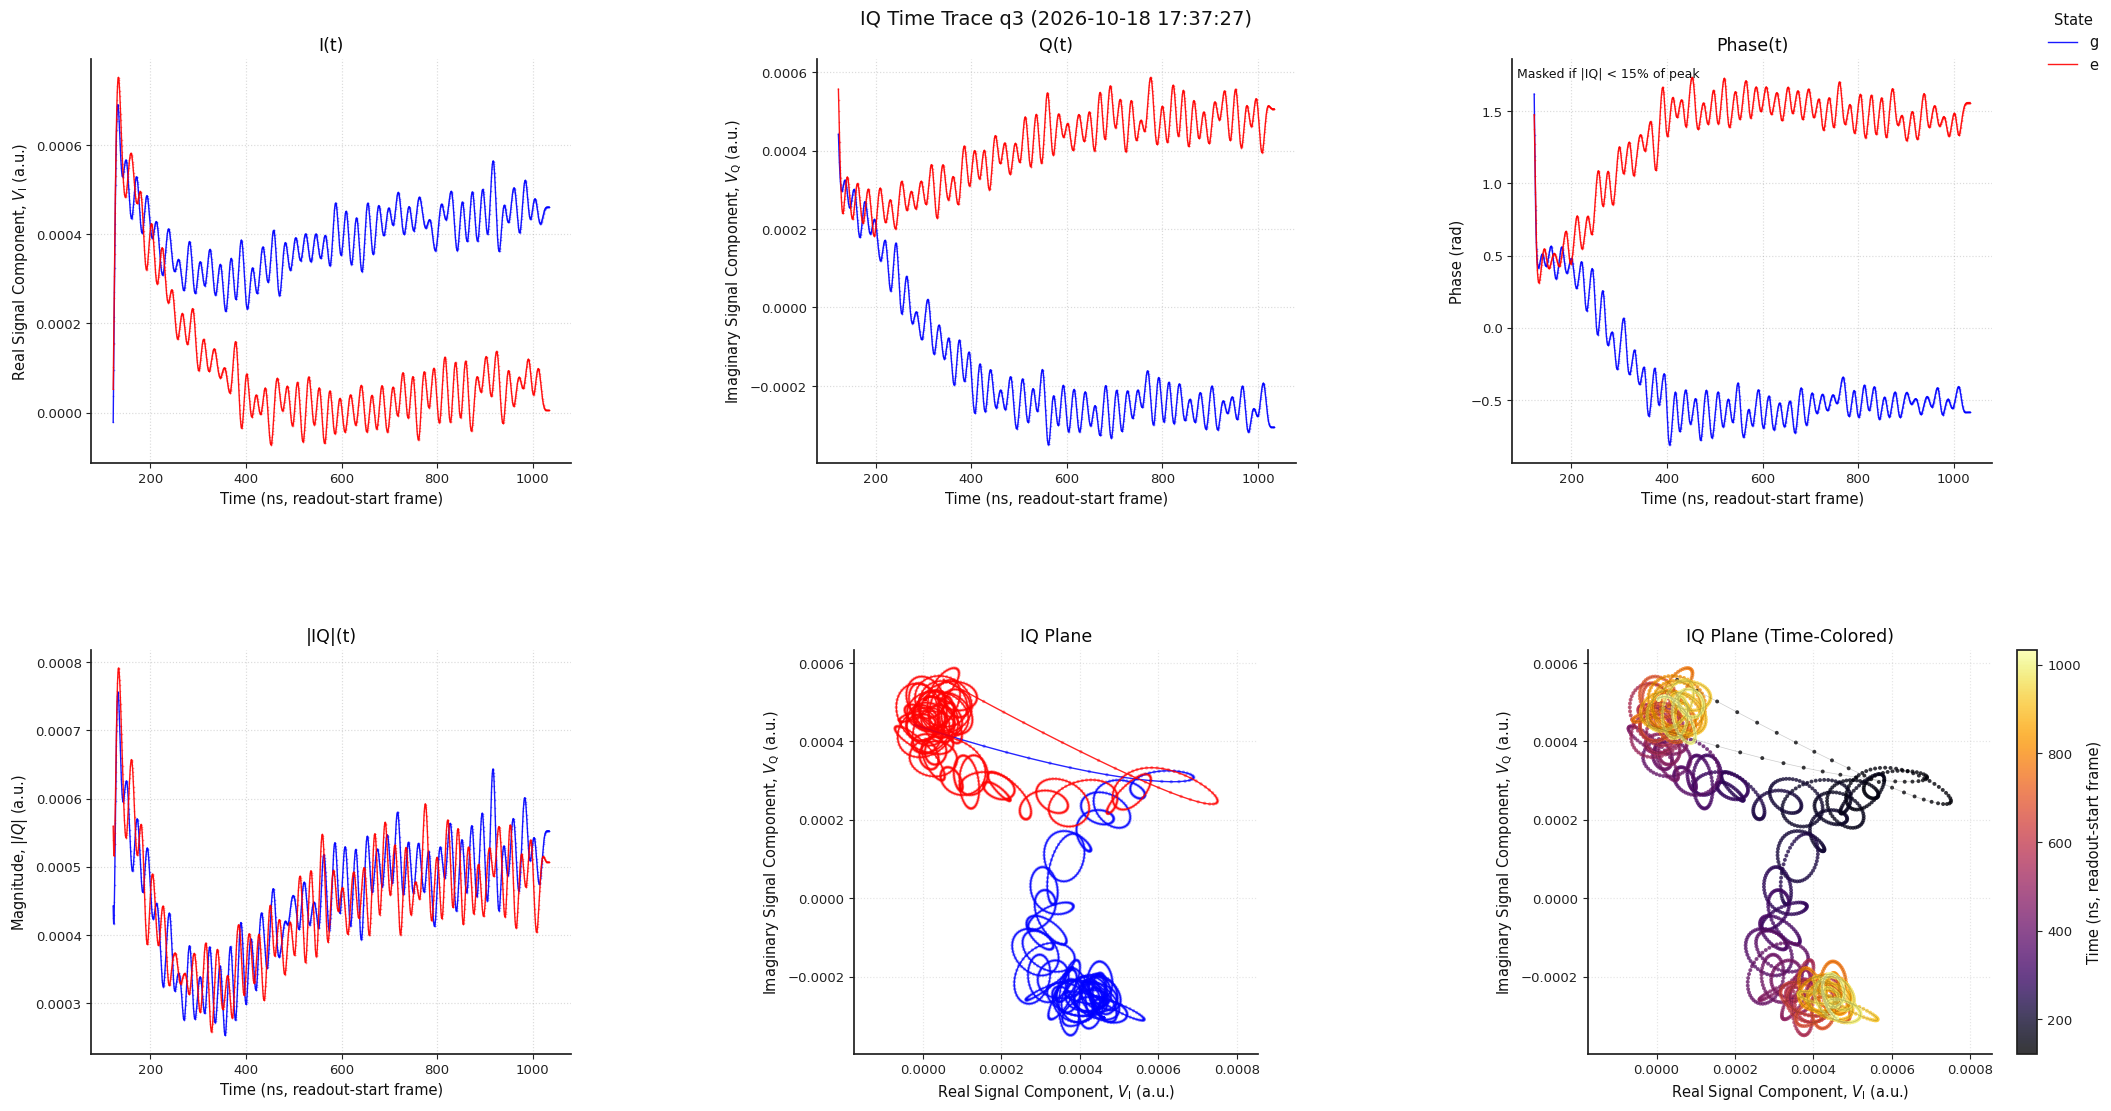

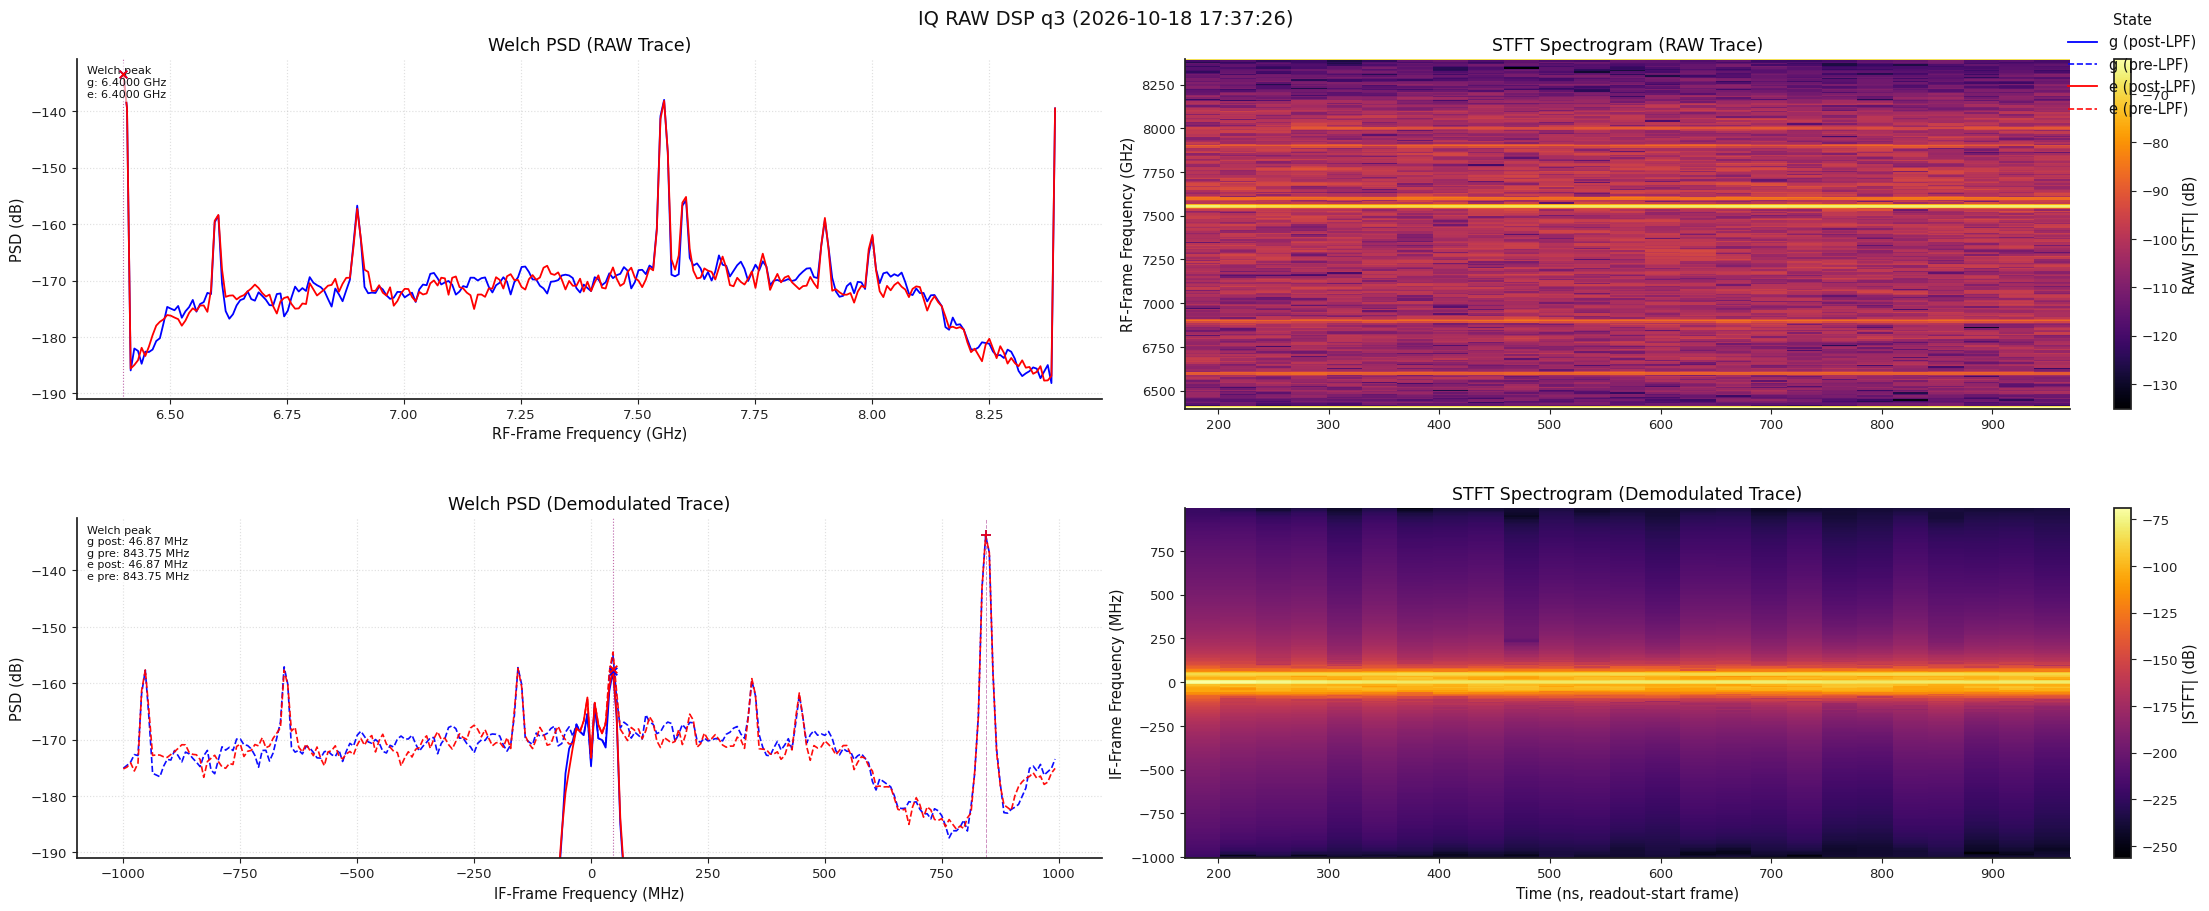

In [144]:
import importlib
import qubit_experiment.analysis.iq_time_trace as a_iqt
import qubit_experiment.experiments.iq_time_trace as e_iqt
from IPython.display import display

importlib.reload(a_iqt)
importlib.reload(e_iqt)

###################################################################################
q=qubits[2]
temporary_parameters = {}
temp_pars =deepcopy(q.parameters)
# temp_pars.readout_integration_delay = 244e-9#500e-9
#temp_pars.readout_resonator_frequency = 7.3445e9
# temp_pars.readout_resonator_frequency = 7.5546e9
# temp_pars.readout_integration_length = 1e-6
temporary_parameters[q.uid] = temp_pars
#######################################################################
print(f"DRIVE range (dBm) : {q.parameters.drive_range}, READOUT range (dBm) : {q.parameters.readout_range_out}")
print(q.readout_parameters())
#######################################################################
opts = e_iqt.experiment_workflow.options()
#options.count(2**14)
opts.do_analysis(True)
opts.apply_software_demodulation(True)
opts.apply_lpf_after_demodulation(True)
opts.count(1024*8)
opts.lpf_cutoff_frequency_hz(50e6)
opts.find_flat_window(False)
#opts.update(True)


#print(workflow.show_fields(options))

###################################################################
iq_t = e_iqt.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits=q.uid,
    options=opts,
    states='ge',
    temporary_parameters=temporary_parameters
)

iq_trace_result = iq_t.run()
#qubit_spec_compiled = session.compile(amplitude_rabi.create_experiment(qpu=qpu,qubit=q,amplitudes=amplitudes, options=options))
display(iq_trace_result.tasks['analysis_workflow'].tasks['plot_iq_time_traces'].output[q.uid])
try:
    display(iq_trace_result.tasks['analysis_workflow'].tasks['plot_iq_dsp'].output[q.uid])
    display(iq_trace_result.tasks['analysis_workflow'].tasks['plot_flat_window_debug'].output[q.uid])
except KeyError:
    pass


In [124]:
qubits[2].parameters.readout_resonator_frequency

7553833333.333333

In [ ]:
fw = iq_trace_result.tasks["analysis_workflow"].output["flat_window_detection"][q.uid]
print(fw["expected_length_samples"], fw["allowed_min_sep_samples"], fw["allowed_max_sep_samples"])


In [ ]:
iq_trace_result.tasks['analysis_workflow'].output["new_parameter_values"]

# SAVE QPU

In [153]:
from datetime import datetime
from laboneq.serializers import save

save_folder = PROJECT_ROOT / "qpu_parameters"
save_folder.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
filename = "1"
save_path = save_folder / f"{timestamp}_{filename}.json"
save(qpu, filename=save_path)
print(f"Saved QPU: {save_path}")


Saved QPU: /Users/yalgaeahn/Research/20_Projects/qubit-experiment/projects/2026_alltoall_kps/qpu_parameters/20261018-191315_1.json


In [130]:
import numpy as np
from qubit_experiment.experiments import coherence_tracking

options = coherence_tracking.experiment_workflow.options()
options.logstore([])
options.tracked_parameters("coherence")
options.total_duration_s(12 * 3600)
options.interval_s(300)
options.track_frequency(True)
options.update(False)
options.continue_on_iteration_error(True)
options.do_plotting(True)
options.monitoring_directory("/absolute/path/to/new-overnight-run")
options.history_path("/absolute/path/to/coherence-history.jsonl")

output = coherence_tracking.experiment_workflow(
    session=session,
    qpu=qpu,
    qubits="q0",
    t1_delays=np.linspace(0, 150e-6, 61),
    t2_star_delays=np.linspace(0, 80e-6, 161),
    t2_delays=np.linspace(0, 150e-6, 61),
    t2_star_detunings=100e3,
    options=options,
).run().output

KeyError: 'q0'